# TP3 · Language models in the matching pipeline

*Data Matching course · M2 MIAGE · Session 3 of 3 · Student version*

| Session | Notebook | Topic |
|---|---|---|
| 1 | TP1 | Know the data, standardise it, build and compare candidate pairs |
| 2 | TP2 | Decide and evaluate; discover language models |
| **3** | **TP3** | **Language models in the matching pipeline** |

We take the classical pipeline of TP1 and TP2 and we revisit **each step** with a language model. For each step: the classical method, its limit, what the language model brings, and at what cost.

| Part | Step | Classical method | Its limit | With a language model | Practice |
|---|---|---|---|---|---|
| 1 | Standardisation | hand-written rules (TP1) | free text, unexpected formats | a generative model splits an address | ≈ 15 min |
| 2 | Pairing | blocking keys, multi-pass (TP1) | a typo in the key loses the pair | nearest neighbours of the record vectors | ≈ 10 min |
| 3 | Comparison | Jaro–Winkler, edit distance (TP1) | compares letters, not meaning | similarity of the vectors, as one more attribute | ≈ 10 min |
| 4 | Decision | logistic regression (TP2) | hesitates in the grey zone | a generative model as a judge, in a cascade (bonus: a trained encoder) | ≈ 30 min |
| 5 | Evaluation | precision, recall, F1 | says nothing about the cost | the same measures, plus the **time** | ≈ 10 min |

Everything is free and runs on a laptop CPU: no subscription, no paid token, and the personal data stay on the machine.

## 0. Set-up

**Packages.** Run the commands of the next cell once (remove the `#`).

**Ollama.** Install Ollama (https://ollama.com), then run in a terminal: `ollama pull qwen3.5:2b` (about 2.7 GB). Download it **before** the session.

In [32]:
#!pip install recordlinkage scikit-learn matplotlib sentence-transformers ollama pydantic
# On Linux, install the CPU-only PyTorch first (much smaller download):
#!pip install torch --index-url https://download.pytorch.org/whl/cpu

In [33]:
import os

HF_CACHE = r"D:\AI\HuggingFace"
ST_CACHE = r"D:\AI\HuggingFace\sentence-transformers"

os.environ["HF_HOME"] = HF_CACHE
os.environ["SENTENCE_TRANSFORMERS_HOME"] = ST_CACHE

os.makedirs(ST_CACHE, exist_ok=True)

In [34]:
# Switches: set a value to False to skip a part (for instance, to save time).
RUN_EMBEDDINGS = True    # steps 2 and 3: sentence embeddings (about 90 MB download)
RUN_FINETUNING = False   # bonus 4.2: training of a small encoder (a few minutes on a CPU)
RUN_OLLAMA = True        # steps 1 and 4.1: generative model served by Ollama

EMB_MODEL = "sentence-transformers/all-MiniLM-L6-v2"   # small encoder (22 million parameters)
OLLAMA_MODEL = "qwen3.5:0.8b"                            # or "qwen3.5:0.8b" (faster, less accurate)
MAX_LLM_CALLS = 100      # maximum number of pairs sent to the generative model in one experiment
SEED = 42

In [35]:
import os, re, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import recordlinkage
from recordlinkage.datasets import load_febrl2
from recordlinkage.index import Block, SortedNeighbourhood
from sklearn.linear_model import LogisticRegression

random.seed(SEED)
np.random.seed(SEED)
results = []     # one row per matching method (final table)
idx_rows = []    # one row per pairing method

### 0.1 Rebuild the classical pipeline of TP1 and TP2

The next four cells repeat TP1 and TP2 in a compact form: cleaning, multi-pass pairing, comparison, train/test split by person, and logistic regression. Run them. You do not need to read them in detail: everything was explained in TP1 and TP2. (≈ 15 min with the installation.)

In [36]:
# Data, cleaning (TP1) and serialisation (TP2, Part 4)
df_raw, true_links = load_febrl2(return_links=True)
ATTRIBUTES = list(df_raw.columns)
last_words = df_raw["address_1"].str.upper().str.split().str[-1].value_counts()
STREET_TYPES = last_words[last_words >= 20].index.tolist()

def clean(data):
    out = data.copy()
    for col in ATTRIBUTES:
        s = out[col].str.upper()
        s = s.str.replace(r"[^\w\s]", " ", regex=True)
        s = s.str.replace(r"\s+", " ", regex=True).str.strip()
        out[col] = s.replace("", np.nan)
    out["postcode"] = out["postcode"].str.replace(r"\D", "", regex=True).replace("", np.nan)
    pattern = r"\b(" + "|".join(map(re.escape, STREET_TYPES)) + r")\b"
    s = out["address_1"].str.replace(pattern, " ", regex=True)
    out["address_1_clean"] = s.str.replace(r"\s+", " ", regex=True).str.strip().replace("", np.nan)
    return out

df = clean(df_raw)
N = len(df)

def record_to_text(rec):
    # One record -> "given name: sarah; surname: bruhn; ...". Missing values are skipped.
    return "; ".join(f"{col.replace('_', ' ')}: {rec[col]}" for col in ATTRIBUTES if pd.notna(rec[col]))

record_text = df[ATTRIBUTES].apply(record_to_text, axis=1).str.lower()
print(record_text.iloc[0])

given name: sarah; surname: bruhn; street number: 44; address 1: forbes street; address 2: wintersloe; suburb: kellerberrin; postcode: 4510; state: vic; date of birth: 19300213; soc sec id: 7535316


In [37]:
# Tools of TP1 and TP2: pair numbers, quality of a pairing, evaluation, choice of a threshold
def pair_keys(pairs):
    a = df.index.get_indexer(pairs.get_level_values(0))
    b = df.index.get_indexer(pairs.get_level_values(1))
    return np.minimum(a, b).astype(np.int64) * N + np.maximum(a, b)

def make_pairs(keys):
    keys = np.unique(keys)
    ids = df.index.to_numpy()
    return pd.MultiIndex.from_arrays([ids[keys % N], ids[keys // N]], names=["rec_id_1", "rec_id_2"])

TRUE_ALL = np.unique(pair_keys(true_links))

def indexing_quality(pairs, name):
    keys = np.unique(pair_keys(pairs))
    row = {"pairing": name, "pairs": len(keys),
           "pair completeness": round(float(np.isin(TRUE_ALL, keys).mean()), 4),
           "reduction ratio": round(1 - len(keys) / (N * (N - 1) / 2), 4)}
    idx_rows.append(row)
    return row

def evaluate(pred_pairs, true_keys, name, record=True):
    pred = np.unique(pair_keys(pred_pairs))
    tp = int(np.isin(pred, true_keys).sum())
    fp, fn = len(pred) - tp, len(true_keys) - tp
    precision = tp / (tp + fp) if tp + fp > 0 else 0.0
    recall = tp / (tp + fn) if tp + fn > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall > 0 else 0.0
    row = {"method": name, "TP": tp, "FP": fp, "FN": fn,
           "precision": round(precision, 4), "recall": round(recall, 4), "F1": round(f1, 4)}
    if record:
        results.append(row)
    return row

def best_threshold(scores, labels):
    scores, labels = np.asarray(scores, dtype=float), np.asarray(labels, dtype=bool)
    order = np.argsort(-scores)
    s, y_sorted = scores[order], labels[order]
    tp, fp = np.cumsum(y_sorted), np.cumsum(~y_sorted)
    precision, recall = tp / (tp + fp), tp / max(y_sorted.sum(), 1)
    f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-12)
    f1 = np.where(np.r_[s[1:] != s[:-1], True], f1, -1)
    i = int(np.argmax(f1))
    return s[i], f1[i]

def show_pair(a, b):
    return df.loc[[a, b], ATTRIBUTES].T

In [38]:
# Multi-pass pairing, comparison vectors, train/test split by person
passes = [SortedNeighbourhood(left_on="surname", window=5), SortedNeighbourhood(left_on="given_name", window=5),
          Block(left_on="postcode"), Block(left_on="date_of_birth"), Block(left_on="soc_sec_id")]
candidates = None
for algorithm in passes:
    p = algorithm.index(df)
    candidates = p if candidates is None else candidates.union(p)
candidates = make_pairs(pair_keys(candidates))
indexing_quality(candidates, "multi-pass (5 keys)")

cmp = recordlinkage.Compare()
for col, method in [("given_name", "jarowinkler"), ("surname", "jarowinkler"), ("street_number", "levenshtein"),
                    ("address_1_clean", "jarowinkler"), ("address_2", "jarowinkler"), ("suburb", "jarowinkler"),
                    ("postcode", "levenshtein"), ("date_of_birth", "levenshtein"), ("soc_sec_id", "levenshtein")]:
    cmp.string(col, col, method=method, label=col.replace("_clean", ""))
cmp.exact("state", "state", label="state")
features = cmp.compute(candidates, df)
y = np.isin(pair_keys(features.index), TRUE_ALL)

entity = pd.Series(df.index.str.extract(r"rec-(\d+)-", expand=False), index=df.index)
rng = np.random.default_rng(SEED)
all_entities = entity.unique()
in_test = entity.isin(set(rng.choice(all_entities, size=len(all_entities) // 2, replace=False)))

def split_masks(pairs):
    a = in_test.reindex(pairs.get_level_values(0)).to_numpy(dtype=bool)
    b = in_test.reindex(pairs.get_level_values(1)).to_numpy(dtype=bool)
    return (~a & ~b), (a & b)

train_mask, test_mask = split_masks(features.index)
_, test_part = split_masks(true_links)
TRUE_TEST = np.unique(pair_keys(true_links[test_part]))
test_pairs = features.index[test_mask]
print(f"{len(features):,d} candidate pairs | train: {train_mask.sum():,d} | test: {test_mask.sum():,d} ({len(TRUE_TEST)} true pairs)")

183,773 candidate pairs | train: 46,479 | test: 46,568 (961 true pairs)


In [39]:
# The classical reference: logistic regression (TP2, Part 3)
def train_and_evaluate(X, name):
    model = LogisticRegression(max_iter=1000).fit(X[train_mask], y[train_mask])
    threshold, _ = best_threshold(model.predict_proba(X[train_mask])[:, 1], y[train_mask])
    p_test = model.predict_proba(X[test_mask])[:, 1]
    print(evaluate(X.index[test_mask][p_test >= threshold], TRUE_TEST, name))
    return model, threshold, p_test

logreg, t_lr, p_lr_test = train_and_evaluate(features, "TP2 reference: logistic regression")
p_lr_train = logreg.predict_proba(features[train_mask])[:, 1]

{'method': 'TP2 reference: logistic regression', 'TP': 955, 'FP': 2, 'FN': 6, 'precision': 0.9979, 'recall': 0.9938, 'F1': 0.9958}


## 1. Step 1 · Standardisation: a generative model splits an address

**Classical method (TP1).** Hand-written rules: upper case, symbols, street types, regular expressions.

**Its limit.** Real addresses are often one free-text string, with many formats: abbreviations, missing commas, extra information (apartment, *cedex*). Writing rules for every format is long and fragile.

**With a language model.** We ask a generative model to split the text into fields. We impose the **format** of the answer (a JSON object with fixed fields), and we tell it to copy the values without inventing anything.

The *Febrl2* attributes are already split into fields, so we use a few French addresses written by hand.

In [40]:
if RUN_OLLAMA:
    try:
        import ollama
        from pydantic import BaseModel
        from typing import Optional

        def llm_json(messages, schema):
            # Ask the local model for an answer that follows a JSON schema. Temperature 0: reproducible.
            kwargs = dict(model=OLLAMA_MODEL, messages=messages, format=schema.model_json_schema(),
                          options={"temperature": 0, "seed": SEED, "num_ctx": 2048})
            try:
                response = ollama.chat(think=False, **kwargs)   # no "thinking" step: faster on a CPU
            except (TypeError, ollama.ResponseError):
                response = ollama.chat(**kwargs)                # old client, or model without thinking mode
            return schema.model_validate_json(response["message"]["content"])

        class Address(BaseModel):
            street_number: Optional[str]
            street_type: Optional[str]
            street_name: Optional[str]
            postcode: Optional[str]
            city: Optional[str]

        def parse_address(text):
            messages = [{"role": "system", "content": "Split the French postal address into fields. Copy the values "
                         "from the text. Do not invent any value: use null if a field is absent."},
                        {"role": "user", "content": text}]
            return llm_json(messages, Address)

        t0 = time.time()
        print(parse_address("12 bis, r. Jean Jaurès - 31000 TOULOUSE"),
              f"({time.time() - t0:.1f} s, the first call also loads the model)")
    except Exception as error:
        RUN_OLLAMA = False
        print("Ollama is not ready: steps 1 and 4.2 are skipped. Error:", error)
        print(f"Install Ollama (https://ollama.com), start it, then run in a terminal: ollama pull {OLLAMA_MODEL}")

Ollama is not ready: steps 1 and 4.2 are skipped. Error: Failed to connect to Ollama. Please check that Ollama is downloaded, running and accessible. https://ollama.com/download
Install Ollama (https://ollama.com), start it, then run in a terminal: ollama pull qwen3.5:0.8b


In [ ]:
RAW_ADDRESSES = [
    "12 bis, r. Jean Jaurès - 31000 TOULOUSE",
    "2 rue du Doyen-Gabriel-Marty 31042 Toulouse cedex 9",
    "Appt 3, 5 av. de la République, 75011 Paris",
]


def parse_and_check(texts):
    rows = []
    for text in texts:
        parsed = parse_address(text).model_dump()
        postcode = parsed["postcode"] or ""
        # Two simple controls: a French postcode has 5 digits, and it must appear in the input text.
        parsed["postcode has 5 digits"] = bool(re.fullmatch(r"\d{5}", postcode))
        parsed["postcode in the text"] = postcode != "" and postcode in text
        rows.append({"raw text": text, **parsed})
    return pd.DataFrame(rows)


if RUN_OLLAMA:
    display(parse_and_check(RAW_ADDRESSES))

**What to observe.** The model handles formats that a simple rule would miss. However, it can **invent** a value (a *hallucination*) or put a value in the wrong field. We therefore add simple **controls** to every answer. Each address costs one call to the model: we use it only for the records that the rules cannot parse.

### Exercise 1 · Control the parsing

<font color='red'>

***To do***: add two messy addresses of your own to `RAW_ADDRESSES` (for instance, without postcode, or with a postcode written with a space). Find a case where the model invents or misplaces a value. How can a program detect it automatically?

</font>

In [ ]:
# Your code here

# Two messy French addresses
extra_addresses = [
    "Appt 8, 14 rue des Roses, Toulouse",
    "5 av. Victor Hugo, 31 000 Toulouse"
]

# Test the original and new addresses
test_addresses = RAW_ADDRESSES + extra_addresses

results_ex1 = parse_and_check(test_addresses)
display(results_ex1)


,raw text,street_number,street_type,street_name,postcode,city,postcode has 5 digits,postcode in the text
0,"12 bis, r. Jean Jaurès - 31000 TOULOUSE",12,bis,Jean Jaurès,31000,TOULOUSE,True,True
1,2 rue du Doyen-Gabriel-Marty 31042 Toulouse ce...,2,rue,du Doyen-Gabriel-Marty,31042,Toulouse,True,True
2,"Appt 3, 5 av. de la République, 75011 Paris",Appt 3,5,av. de la République,75011,Paris,True,True
3,"Appt 8, 14 rue des Roses, Toulouse",Appt 8,rue,des Roses,Toulouse,Toulouse,False,True
4,"5 av. Victor Hugo, 31 000 Toulouse",5,av.,Victor Hugo,31 000,Toulouse,False,True


*Your answer:*

...

## 2. Step 2 · Pairing by nearest neighbours

**Classical method (TP1, Part 3).** Blocking keys and multi-pass pairing.

**Its limit.** We must choose the keys by hand, and a typo in a key loses the pair for this key.

**With a language model.** The encoder turns each record into a vector (TP2, Part 4). For each record, we keep its *K* nearest neighbours as candidate pairs. No key to choose.

In [44]:
if RUN_EMBEDDINGS:
    from sentence_transformers import SentenceTransformer
    from sklearn.neighbors import NearestNeighbors

    encoder = SentenceTransformer(EMB_MODEL, device="cpu", cache_folder=ST_CACHE)
    
    t0 = time.time()
    E = encoder.encode(
        record_text.tolist(),
        batch_size=64,
        normalize_embeddings=True,
        show_progress_bar=True,
    )
    print(f"{E.shape[0]} records x {E.shape[1]} numbers in {time.time() - t0:.0f} s")

    def knn_pairs(K):
        # Each record with its K nearest neighbours (cosine). Returns the pair numbers.
        nn = NearestNeighbors(n_neighbors=K + 1, metric="cosine").fit(E)
        _, neighbours = nn.kneighbors(E)
        rows = np.repeat(np.arange(N), K + 1)
        cols = neighbours.ravel()
        keep = rows != cols  # remove the pairs (a, a)
        return np.unique(
            np.minimum(rows[keep], cols[keep]).astype(np.int64) * N
            + np.maximum(rows[keep], cols[keep])
        )

    K = 10
    emb_keys = knn_pairs(K)
    indexing_quality(make_pairs(emb_keys), f"nearest neighbours, K = {K}")
    indexing_quality(
        make_pairs(np.union1d(pair_keys(candidates), emb_keys)),
        "multi-pass + nearest neighbours",
    )
pd.DataFrame(idx_rows)

Batches: 100%|██████████| 79/79 [00:36<00:00,  2.19it/s]


5000 records x 384 numbers in 36 s


,pairing,pairs,pair completeness,reduction ratio
0,multi-pass (5 keys),183773,1.0000,0.9853
1,"nearest neighbours, K = 10",39053,0.9323,0.9969
2,multi-pass + nearest neighbours,201752,1.0000,0.9839


**What to observe.** Compare the number of pairs and the pair completeness with the multi-pass pairing. On *Febrl2*, the hand-made keys are already very good: the nearest neighbours bring few new true pairs. This pairing is most useful when no good key exists, for instance with free text (product descriptions, company names). The two methods can be combined (union).

## 3. Step 3 · Comparison: the meaning as one more attribute

**Classical method (TP1, Part 4).** Jaro–Winkler and the edit distance compare letters, attribute by attribute.

**Its limit.** They do not know the meaning: *Bill* and *William* look very different.

**With a language model.** We add one column to the comparison vector: the cosine of the two record vectors. Then we train the same logistic regression as in TP2, and we measure the gain.

In [45]:
def cosine_of_pairs(E, pairs, batch=20000):
    # Cosine of the two records of each pair (the vectors are already normalised).
    a = df.index.get_indexer(pairs.get_level_values(0))
    b = df.index.get_indexer(pairs.get_level_values(1))
    return np.concatenate([np.sum(E[a[i:i + batch]] * E[b[i:i + batch]], axis=1) for i in range(0, len(a), batch)])

if RUN_EMBEDDINGS:
    features_emb = features.copy()
    features_emb["embedding_cosine"] = cosine_of_pairs(E, features.index)
    _ = train_and_evaluate(features_emb, "logistic regression + embedding similarity")

{'method': 'logistic regression + embedding similarity', 'TP': 955, 'FP': 2, 'FN': 6, 'precision': 0.9979, 'recall': 0.9938, 'F1': 0.9958}


**What to observe.** On *Febrl2*, the gain is often small: the 10 classical scores already describe the pairs well. The gain is larger with textual or heterogeneous data.

### Exercise 2 · How many neighbours?

<font color='red'>

***To do***: run the pairing by nearest neighbours (step 2) with K = 5, 10, 20 and 40. Plot the pair completeness against the number of pairs. What do you gain, and what does it cost, when K increases?

</font>

,K,pairs,pair completeness
0,5,19537,0.9209
1,10,39053,0.9323
2,20,78609,0.9545
3,40,160733,0.9710


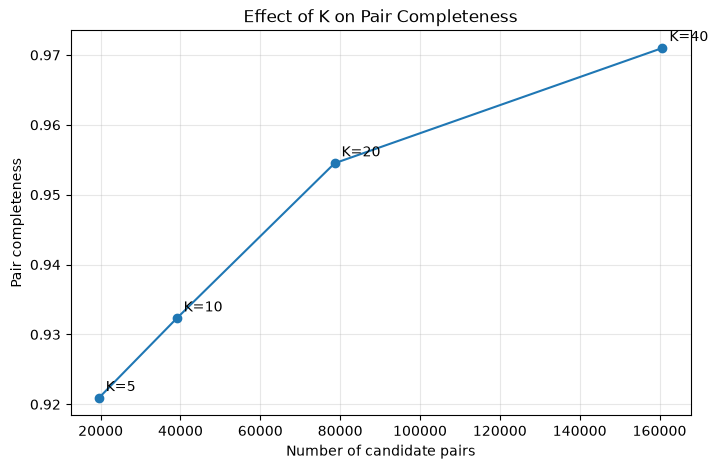

In [46]:
# Your code here


# Exercise 2 - How many neighbours?

k_values = [5, 10, 20, 40]
ex2_rows = []

for k in k_values:
    keys = knn_pairs(k)
    pairs = make_pairs(keys)

    quality = indexing_quality(
        pairs,
        f"nearest neighbours, K = {k}"
    )

    ex2_rows.append({
        "K": k,
        "pairs": quality["pairs"],
        "pair completeness": quality["pair completeness"]
    })

# Display the results
ex2_results = pd.DataFrame(ex2_rows)
display(ex2_results)

# Plot pair completeness vs number of pairs
plt.figure(figsize=(8, 5))

plt.plot(
    ex2_results["pairs"],
    ex2_results["pair completeness"],
    marker="o"
)

for _, row in ex2_results.iterrows():
    plt.annotate(
        f"K={int(row['K'])}",
        (row["pairs"], row["pair completeness"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel("Number of candidate pairs")
plt.ylabel("Pair completeness")
plt.title("Effect of K on Pair Completeness")
plt.grid(True, alpha=0.3)
plt.show()


*Your answer:*

...

## 4. Step 4 · Decision

**Classical method (TP2).** The logistic regression gives a probability. It is very good for clear cases.

**Its limit.** It hesitates in the grey zone (TP2, Part 3).

**With a language model.** A model that reads the two records **as texts** decides the uncertain pairs. It is much slower than the logistic regression, so we use it in a **cascade**: the logistic regression decides the clear cases, and the expensive model decides only the grey zone.
* **4.1 A generative model as a judge** (main practice). It needs no training: only two solved examples in the prompt.
* **4.2 Bonus: an encoder trained on our pairs** (a *cross-encoder*), for the fast students. Switched off by default (`RUN_FINETUNING = False`).

### 4.1 A generative model as a judge

We ask the generative model: "Do these two records describe the same person?". The prompt has three parts:
1. a **system** message: the role and the task, with the usual kinds of errors;
2. two **solved examples** taken from the train part (*few-shot*): the most difficult true pair and the most difficult non-match, according to the logistic regression;
3. the **pair to judge**.

The answer must follow a fixed format: `{"same_person": true}` or `{"same_person": false}`.

In [47]:
SYSTEM_PROMPT = ("You are an expert in data quality. You compare two records from a population register. "
                 "Records can contain typos, missing values, swapped values or abbreviations. "
                 "Decide if the two records describe the same real person. "
                 'Answer in JSON: {"same_person": true} or {"same_person": false}.')

def pair_prompt(id_a, id_b):
    return f"Record A: {record_text[id_a]}\nRecord B: {record_text[id_b]}\nDo these two records describe the same person?"

# Two solved examples from the TRAIN part: the most difficult match and the most difficult non-match.
train_pairs_idx = features.index[train_mask]
y_tr = y[train_mask]
hardest_match = train_pairs_idx[y_tr][np.argmin(p_lr_train[y_tr])]
hardest_non_match = train_pairs_idx[~y_tr][np.argmax(p_lr_train[~y_tr])]
FEW_SHOT = [(hardest_match, True), (hardest_non_match, False)]

def build_messages(id_a, id_b):
    messages = [{"role": "system", "content": SYSTEM_PROMPT}]
    for (ea, eb), label in FEW_SHOT:
        messages.append({"role": "user", "content": pair_prompt(ea, eb)})
        messages.append({"role": "assistant", "content": '{"same_person": %s}' % str(label).lower()})
    messages.append({"role": "user", "content": pair_prompt(id_a, id_b)})
    return messages

# The full prompt for one test pair
for m in build_messages(*test_pairs[0]):
    print(f"[{m['role']}] {m['content']}\n")

[system] You are an expert in data quality. You compare two records from a population register. Records can contain typos, missing values, swapped values or abbreviations. Decide if the two records describe the same real person. Answer in JSON: {"same_person": true} or {"same_person": false}.

[user] Record A: given name: lachlan; surname: salt; street number: 37; address 2: elensra; suburb: ivanhoe; postcode: 3102; state: nsw; soc sec id: 2154434
Record B: given name: lachan; surname: sal t; street number: 37; address 1: port jackson circuit; suburb: ivanhoe; postcode: 3102; state: nsw; date of birth: 19270329; soc sec id: 2059611
Do these two records describe the same person?

[assistant] {"same_person": true}

[user] Record A: given name: elly; surname: mitton; street number: 8; address 1: port jackson circuit; address 2: mayflower retrmnt vlge; suburb: whalan; postcode: 2830; state: wa; date of birth: 19900424; soc sec id: 5694037
Record B: given name: isabella; surname: campbell; 

In [52]:
RUN_OLLAMA = True

print("RUN_OLLAMA:", RUN_OLLAMA)
print("Model:", OLLAMA_MODEL)

RUN_OLLAMA: True
Model: qwen3.5:0.8b


In [53]:
if RUN_OLLAMA:
    class Decision(BaseModel):
        same_person: bool

    def llm_judge(id_a, id_b):
        return llm_json(build_messages(id_a, id_b), Decision).same_person

    def run_judge(pairs, name):
        # Ask the judge for each pair. Prints the time per pair.
        t0, answers = time.time(), []
        for i, (a, b) in enumerate(pairs, start=1):
            answers.append(bool(llm_judge(a, b)))
            if i % 10 == 0:
                print(f"  {name}: {i}/{len(pairs)} pairs, {(time.time() - t0) / i:.1f} s per pair")
        return np.array(answers, dtype=bool)

    t0 = time.time()
    print("Test on the hardest train match:", llm_judge(*hardest_match), f"({time.time() - t0:.1f} s)")

Test on the hardest train match: False (6.8 s)


**First test: the judge alone, on a difficult sample.** We take 50 true pairs and the 50 non-matches that look the most like matches (test part). We compare the judge with the logistic regression on the same 100 pairs.

In [54]:
def sample_scores(pred, labels):
    tp = int((pred & labels).sum()); fp = int((pred & ~labels).sum()); fn = int((~pred & labels).sum())
    p = tp / (tp + fp) if tp + fp else 0.0
    r = tp / (tp + fn) if tp + fn else 0.0
    return {"TP": tp, "FP": fp, "FN": fn, "precision": round(p, 3), "recall": round(r, 3),
            "F1": round(2 * p * r / (p + r), 3) if p + r else 0.0}

rng = np.random.default_rng(SEED)
y_te = y[test_mask]
pos = np.where(y_te)[0]
pos = pos[rng.choice(len(pos), size=min(MAX_LLM_CALLS // 2, len(pos)), replace=False)]
neg = np.where(~y_te)[0]
neg = neg[np.argsort(-p_lr_test[neg])][:MAX_LLM_CALLS // 2]
sample_idx = np.r_[pos, neg]
sample_labels = y_te[sample_idx]
print("Logistic regression on the sample:", sample_scores(p_lr_test[sample_idx] >= t_lr, sample_labels))
if RUN_OLLAMA:
    pred_llm = run_judge(test_pairs[sample_idx], OLLAMA_MODEL)
    print(f"{OLLAMA_MODEL} on the sample:", sample_scores(pred_llm, sample_labels))

Logistic regression on the sample: {'TP': 50, 'FP': 2, 'FN': 0, 'precision': 0.962, 'recall': 1.0, 'F1': 0.98}
  qwen3.5:0.8b: 10/100 pairs, 3.0 s per pair
  qwen3.5:0.8b: 20/100 pairs, 3.0 s per pair
  qwen3.5:0.8b: 30/100 pairs, 3.0 s per pair
  qwen3.5:0.8b: 40/100 pairs, 3.0 s per pair
  qwen3.5:0.8b: 50/100 pairs, 3.1 s per pair
  qwen3.5:0.8b: 60/100 pairs, 3.1 s per pair
  qwen3.5:0.8b: 70/100 pairs, 3.1 s per pair
  qwen3.5:0.8b: 80/100 pairs, 3.1 s per pair
  qwen3.5:0.8b: 90/100 pairs, 3.1 s per pair
  qwen3.5:0.8b: 100/100 pairs, 3.1 s per pair
qwen3.5:0.8b on the sample: {'TP': 10, 'FP': 0, 'FN': 40, 'precision': 1.0, 'recall': 0.2, 'F1': 0.333}


**Second test: the judge in a cascade.** The logistic regression decides the clear cases. The judge decides only the pairs of the grey zone (probability between 0.05 and 0.95), at most `MAX_LLM_CALLS` pairs, the closest to 0.5 first. This is the result that enters the final table.

In [56]:
LOW, HIGH = 0.05, 0.95
grey = np.where((p_lr_test >= LOW) & (p_lr_test < HIGH))[0]
grey = grey[np.argsort(np.abs(p_lr_test[grey] - 0.5))][:MAX_LLM_CALLS]
print(f"{len(grey)} pairs in the grey zone are sent to the judge (out of {len(test_pairs):,} test pairs)")
if RUN_OLLAMA:
    decision = p_lr_test >= t_lr
    decision[grey] = run_judge(test_pairs[grey], OLLAMA_MODEL)
    print(evaluate(test_pairs[decision], TRUE_TEST, f"cascade: LR + {OLLAMA_MODEL} on the grey zone"))

78 pairs in the grey zone are sent to the judge (out of 46,568 test pairs)
  qwen3.5:0.8b: 10/78 pairs, 3.1 s per pair
  qwen3.5:0.8b: 20/78 pairs, 3.1 s per pair
  qwen3.5:0.8b: 30/78 pairs, 3.1 s per pair
  qwen3.5:0.8b: 40/78 pairs, 3.1 s per pair
  qwen3.5:0.8b: 50/78 pairs, 3.1 s per pair
  qwen3.5:0.8b: 60/78 pairs, 3.1 s per pair
  qwen3.5:0.8b: 70/78 pairs, 3.1 s per pair
{'method': 'cascade: LR + qwen3.5:0.8b on the grey zone', 'TP': 896, 'FP': 0, 'FN': 65, 'precision': 1.0, 'recall': 0.9324, 'F1': 0.965}


**What to observe.** A small generative model alone is usually weaker than the logistic regression, and much slower. Its value is elsewhere: it needs no training, and it brings knowledge learned from texts (nicknames, abbreviations, place names). In a cascade, it is called on a few pairs only, so the total cost stays low.

### Exercise 3 · Your own prompt

<font color='red'>

***To do***: measure the judge on the difficult sample (step 4.1) in two other settings:
* without the two solved examples (`FEW_SHOT = []`, *zero-shot*);
* with a shorter system message, without the list of usual errors.

Restore `FEW_SHOT` at the end. What changes? Why?

</font>

In [55]:
# Your code here


# Exercise 3 - Compare different prompts

# Save the original configuration
original_few_shot = FEW_SHOT.copy()
original_system_prompt = SYSTEM_PROMPT

# Baseline: original few-shot results from Step 4.1
baseline_scores = sample_scores(pred_llm, sample_labels)

try:
    # Experiment 1: Zero-shot (no examples)
    FEW_SHOT = []

    pred_zero = run_judge(
        test_pairs[sample_idx],
        "Zero-shot"
    )

    zero_scores = sample_scores(pred_zero, sample_labels)

    # Experiment 2: Short system prompt
    FEW_SHOT = original_few_shot

    SYSTEM_PROMPT = (
        "Decide whether two records describe the same person. "
        'Answer in JSON: {"same_person": true} '
        'or {"same_person": false}.'
    )

    pred_short = run_judge(
        test_pairs[sample_idx],
        "Short prompt"
    )

    short_scores = sample_scores(pred_short, sample_labels)

finally:
    # Always restore the original configuration
    FEW_SHOT = original_few_shot
    SYSTEM_PROMPT = original_system_prompt

# Compare the three configurations
comparison_ex3 = pd.DataFrame([
    {"Method": "Original few-shot", **baseline_scores},
    {"Method": "Zero-shot", **zero_scores},
    {"Method": "Short prompt", **short_scores}
])

display(comparison_ex3)


  Zero-shot: 10/100 pairs, 1.3 s per pair
  Zero-shot: 20/100 pairs, 1.3 s per pair
  Zero-shot: 30/100 pairs, 1.3 s per pair
  Zero-shot: 40/100 pairs, 1.3 s per pair
  Zero-shot: 50/100 pairs, 1.3 s per pair
  Zero-shot: 60/100 pairs, 1.3 s per pair
  Zero-shot: 70/100 pairs, 1.3 s per pair
  Zero-shot: 80/100 pairs, 1.3 s per pair
  Zero-shot: 90/100 pairs, 1.3 s per pair
  Zero-shot: 100/100 pairs, 1.3 s per pair
  Short prompt: 10/100 pairs, 3.2 s per pair
  Short prompt: 20/100 pairs, 3.1 s per pair
  Short prompt: 30/100 pairs, 3.1 s per pair
  Short prompt: 40/100 pairs, 3.1 s per pair
  Short prompt: 50/100 pairs, 3.1 s per pair
  Short prompt: 60/100 pairs, 3.1 s per pair
  Short prompt: 70/100 pairs, 3.1 s per pair
  Short prompt: 80/100 pairs, 3.1 s per pair
  Short prompt: 90/100 pairs, 3.1 s per pair
  Short prompt: 100/100 pairs, 3.1 s per pair


,Method,TP,FP,FN,precision,recall,F1
0,Original few-shot,10,0,40,1.0,0.20,0.333
1,Zero-shot,5,0,45,1.0,0.10,0.182
2,Short prompt,11,0,39,1.0,0.22,0.361


*Your answer:*

...

### Exercise 4 · When the judge and the regression disagree

<font color='red'>

***To do***: in the difficult sample, display 3 pairs where the judge and the logistic regression disagree. Who is right? Can you explain the choice of each method?

</font>

In [ ]:
# Your code here

*Your answer:*

...

### 4.2 Bonus: an encoder trained on our pairs (cross-encoder)

*For the fast students. Set `RUN_FINETUNING = True` in the switches (Part 0), then run the three cells below (a few minutes on a CPU).*

We start from the same small encoder as in step 2. We give it pairs of records with their answer (match or non-match), and it learns to decide. It reads the two records **together**, so it can compare them word by word. To keep the training short, we use all true pairs of the train part, plus "difficult" non-matches (the ones that the logistic regression finds the most similar) and "easy" non-matches taken at random. Then it scores only the test pairs that the logistic regression does not reject clearly (cascade).

In [ ]:
if RUN_FINETUNING:
    import torch
    from torch.utils.data import DataLoader
    from transformers import AutoTokenizer, AutoModelForSequenceClassification
    torch.manual_seed(SEED)
    torch.set_num_threads(max(1, (os.cpu_count() or 2) - 1))

    # Training pairs: all matches + difficult non-matches + random non-matches (train part only)
    train_pairs = features.index[train_mask]
    y_train = y[train_mask]
    pos = np.where(y_train)[0]
    neg = np.where(~y_train)[0]
    hard_neg = neg[np.argsort(-p_lr_train[neg])][: 2 * len(pos)]
    rest = np.setdiff1d(neg, hard_neg)
    random_neg = np.random.default_rng(SEED).choice(rest, size=min(2 * len(pos), len(rest)), replace=False)
    chosen = np.concatenate([pos, hard_neg, random_neg])
    train_examples = [(record_text[train_pairs[i][0]], record_text[train_pairs[i][1]], int(y_train[i])) for i in chosen]
    print(f"{len(train_examples)} training pairs ({len(pos)} matches)")

In [ ]:
if RUN_FINETUNING:
    BATCH, MAX_LEN = 16, 128      # 16 pairs at a time; one single pass over the training pairs
    ce_tok = AutoTokenizer.from_pretrained(EMB_MODEL)
    ce_model = AutoModelForSequenceClassification.from_pretrained(EMB_MODEL, num_labels=2)
    # (a warning says that the decision layer is new: this is expected, it is the part we train)

    def collate(batch):
        a, b, labels = zip(*batch)
        enc = ce_tok(list(a), list(b), truncation=True, max_length=MAX_LEN, padding=True, return_tensors="pt")
        enc["labels"] = torch.tensor(labels)
        return enc

    loader = DataLoader(train_examples, batch_size=BATCH, shuffle=True, collate_fn=collate)
    optimizer = torch.optim.AdamW(ce_model.parameters(), lr=3e-5)
    ce_model.train()
    t0, total = time.time(), 0.0
    for step, batch in enumerate(loader, start=1):
        loss = ce_model(**batch).loss     # the error of the model on these 16 pairs
        loss.backward()                   # how to change each parameter to reduce the error
        optimizer.step()                  # a small change of the parameters
        optimizer.zero_grad()
        total += loss.item()
        if step % 50 == 0:
            print(f"  step {step}/{len(loader)}, mean error = {total / step:.4f}")
    print(f"training done in {time.time() - t0:.0f} s")

In [ ]:
if RUN_FINETUNING:
    @torch.no_grad()
    def cross_encoder_proba(pairs, batch_size=64):
        ce_model.eval()
        out = []
        for i in range(0, len(pairs), batch_size):
            chunk = pairs[i:i + batch_size]
            a = record_text.loc[chunk.get_level_values(0)].tolist()
            b = record_text.loc[chunk.get_level_values(1)].tolist()
            enc = ce_tok(a, b, truncation=True, max_length=MAX_LEN, padding=True, return_tensors="pt")
            out.append(torch.softmax(ce_model(**enc).logits, dim=-1)[:, 1].numpy())
        return np.concatenate(out) if out else np.array([])

    to_score = p_lr_test >= 0.01                    # cascade: the cheap filter first
    print(f"{to_score.sum()} test pairs scored by the cross-encoder "
          f"({y[test_mask][~to_score].sum()} true pairs rejected by the filter)")
    t0 = time.time()
    p_ce = cross_encoder_proba(test_pairs[to_score])
    print(f"scoring time: {time.time() - t0:.0f} s")
    print(evaluate(test_pairs[to_score][p_ce >= 0.5], TRUE_TEST, "cascade: LR filter + cross-encoder"))

## 5. Comparison of all methods

All methods are evaluated on the same test part, with the same candidate pairs.

In [ ]:
summary = pd.DataFrame(results).drop_duplicates("method", keep="last").set_index("method")
summary.sort_values("F1", ascending=False)

,TP,FP,FN,precision,recall,F1
method,,,,,,
TP2 reference: logistic regression,955,2,6,0.9979,0.9938,0.9958
logistic regression + embedding similarity,955,2,6,0.9979,0.9938,0.9958


| Approach | Labels needed | Cost on a laptop CPU | Explainability | Most useful when... |
|---|---|---|---|---|
| Logistic regression (TP2) | yes | very low | high (one weight per attribute) | labelled pairs are available |
| Pairing by nearest neighbours | no | low | low | no good blocking key; free text |
| Embedding similarity as an attribute | yes (for the regression) | low | medium | textual attributes |
| Cross-encoder trained on our pairs | yes (a few thousand pairs) | medium (minutes) | low | textual, heterogeneous records |
| Generative model as a judge, in a cascade | no (2 examples) | high per pair, low in total | medium (it can give a reason) | few uncertain pairs; knowledge helps |
| Generative model for parsing | no | high per record | medium | unstructured fields (addresses) |

**Discussion.**
* *Febrl2* is synthetic and well structured. Classical methods already work very well on it, so the gain of language models is small here. Language models bring more value on heterogeneous, textual or multilingual data (for instance, "Univ. Toulouse 1" and "Université Toulouse Capitole").
* The **cascade** is the key design for a laptop: cheap methods on all pairs, expensive methods on few pairs.
* Local models keep personal data on the machine. With an online service, the records of real persons would leave the organisation (GDPR).
* Small models are sensitive to the prompt and to the model version. Write down the model name, the temperature (0) and the seed with the results.

### Exercise 5 · The cost

<font color='red'>

***To do***: from the time per pair printed by `run_judge`, estimate the time needed to send **all** test pairs to the judge. Compare with the cascade. When is a generative model worth its cost?

</font>

In [ ]:
# Your code here

*Your answer:*

...

## Useful links (tools)

* Python Record Linkage Toolkit: https://recordlinkage.readthedocs.io
* Sentence-Transformers: https://www.sbert.net
* Ollama: https://ollama.com